<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW6/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 6

Title: Assignment Analysis

Name: Brennen Cramp

Date: 11/2/2026

---

# Analysis
---

1. The amount of principal components that were required to retain 95% of the total cumulative variance was exactly 123 components. This represents a massive reduction in dimensionality, compressing the original 4,096-dimensional pixel vector by almost 97% while only losing 5% of the statistical information. In Task 3, the reconstruction plots at k=10, show faces that appear highly blurred, smoothed, and facial features are not fully defined such as the eyes, eyebrows, and lips of the people. For subjects like ID: 16, the thin-framed glasses are entirely erased or even appear to be smuged into the skin at lower values of k. Texture and ligthing also appears to vanish at lower values such as skin variations and shadows, leaving behind only the most basic structural aspects of the subjects faces. However, as k values increase, the reconstructed images become almost indistinguishable from the original photos around k=200 and look extremely similar at k=300. By the k=200 threshold (which preserves well over 95% variance), micro-features like the individual frames and reflections of glasses (ID: 16), subtle smiling expressions around the mouth (ID: 8, ID: 24), and sharp eye details are cleanly recovered, matching the source images completely by k=300.

2. The earliest principal components act as global filters that capture massive, dataset-wide variances. For instance, Component 1 (at 23.81%) focuses almost entirely on illumination and lighting direction. It looks deeply washed out because it tracks the overall intensity of ambient light cast across the face. Components 2 and 3 (at 13.99% and 7.97%, respectively) capture directional lighting gradients such as left-to-right or top-to-bottom shadows alongside major facial geometry (wide versus narror face shapes, positioning of hair, and eye sockets). As later principal components appear (Components 4 to 10), they begin extracting prominent physical structures, capturing aspects like the presence of glasses (clearly outlined in Components 7 and 8) or borad mouth shapes and smiles such as in Components 5 and 6. However, these later components appear to increasingly look like fine-grained pixel noise which can be attributed to the PCA model because PCA works by maximizing remaining variance orthogonally, each successive component can only capture what the previous components left behind. By the time Component 15 is reached (explaining only 1.06%), all global lighting and major structural shapes have already been extracted. The remaining variance consists of highly localized, small differences between individuals such as skin texture and exact edge micro-details. When isolated, these high-frequency details lose semantic meaning and appear as abstract, high-contrast pixel noise.

3. It is critical to fit the PCA transformer strictly on the training split rather than on the entire dataset prior to splitting because fitting it on the entire dataset introduces data leakage. PCA computes the dataset mean, standard deviation, and the eigenvectors (direction of maximum variance) across every pixel vector it sees. If the test set is included during this step, information about the distribution, lighting variations, and other features of the test faces are leaked into the training transformation matrix. For negative impacts, if PCA is fitted on the full dataset, the downstream evaluation metrics become artificially inflated and overly optimistic. The principal components will be optimized to represent patterns present in the test split, making the test faces easier for the classifier to interpret. Consequences that may arise would be due to this directly violating the strict separation between training and evaluation data. When deployed in a production setting or tested on truly unseen data, the model's performance will drop sharply because it was evaluated on a compromised pipeline that relied on pre-calculated shortcuts from the test data.

4. Looking at the output of each of the models performance metrics combined together from Task 8: Logistic Regression (Raw) had a test accuracy of 96.2% with 0.96 seconds of training time, Logistic Regression (PCA-Reduced) had a test accuracy of 96.2% with 0.02 seconds of training time, Kernel SVM (RBF) (PCA-Reduced) had a test accuracy of 95.0% with 0.023 seconds of training time, and the Soft Voting Ensemble (PCA-Reduced) had a test accuracy of 95.0% with 0.758 seconds of training time. Non-linear kernels and ensemble methods did not yield accuracy gains over the linear baselines, but instead, both Logistic Regression configurations outpaced them at 96.2%. This demonstrates that the Olivetti Faces dataset is highly linearly separable when normalized such that due to the faces being perfectly centered and tightly cropped, a simple linear decision boundary is fully capable of distinguishing between the 40 subjects. Introducing highly complex non-linear boundaries (RBF SVM) or broad tree structures (such as Random Forest via the Ensemble) actually led to a slight drop in generalization performance, likely due to mild overfitting on the limited samples per subject. With Logistic Regression (Raw) at 96.2%, the narrative becomes clearer that the linear model performs excellently on this dataset regardless of whether it uses the raw pixels or the compressed PCA components. In addition, classical classifiers (linear, non-linear, or ensembles) hit a hard ceiling because they operate on flattened pixel vectors or global projections. These classifiers treat images as flat 1D-structures, destroying all crucial 2D spatial relationships and local geometry, such as the placement of an eye to a nose. Global metrics are very fragile and if an identity of an image shifts by just a few pixels or if a facial expression changes the layout of features, the entire vector changes tremendously. Classical models lack spatial invariance and local feature extraction so they cannot scale beyond highly structured, pre-aligned, and centered datasets like Olivetti.

5. While reducing features down to 123 principal components allowed Logistic Regression (PCA-Reduced) to drop its training time down to 0.02 seconds while maintaining peak accuracy at 96.2%, this performance is a result of a cleaned dataset. Treating images as flattened 1D-vectors or mapping them to global linear sub-spaces strips away the 2D grid-structure of visual data. PCA looks at statistical variances across the entire set at one time, making it essentially blind to localized features that remain consistent. The fact that Logistic Regression (Raw) required 0.960 seconds to reach the exact same 96.2% accuracy as its PCA run shows that adding more raw parameters does not provide any advantage. Classical models map pixel positions in a strict manner and if a face moves by just a few pixels, tilts, or is partially covered in any way, the entire vector could shift completely. These models lack spatial invariance, rendering them not suitable of handling dynamic datasets where objects are not perfectly aligned and centered. Even an adaptive architecture like the Soft Voting Ensemble hit a definitive accuracy ceiling at 95.0% while taking 0.758 seconds to train which proves that classical algorithms cannot add on past the basic limitations of global vector-projections. Complex computer vision tasks need deep feature extraction, so using knowledge from piror classes, CNNs or vision transformers would work for these computer vision tasks. Modern networks extract low-level edges in earlier layers and assemble them spatially, which is a structural capability that does not exist in classical workflows.

# **Sample Faces from Olivetti Dataset (Task 1):**

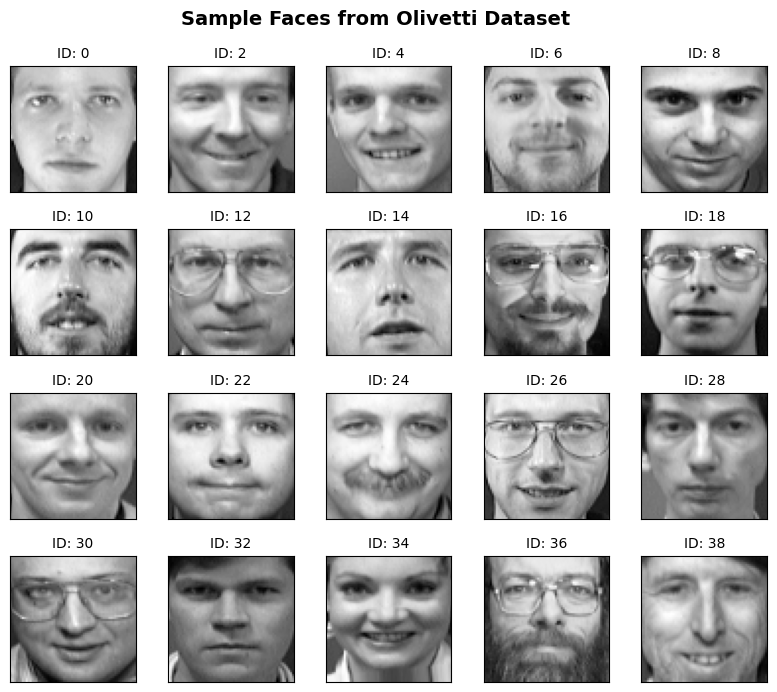

# **PCA Explained Variance vs. Number of Principal Components (Task 2):**

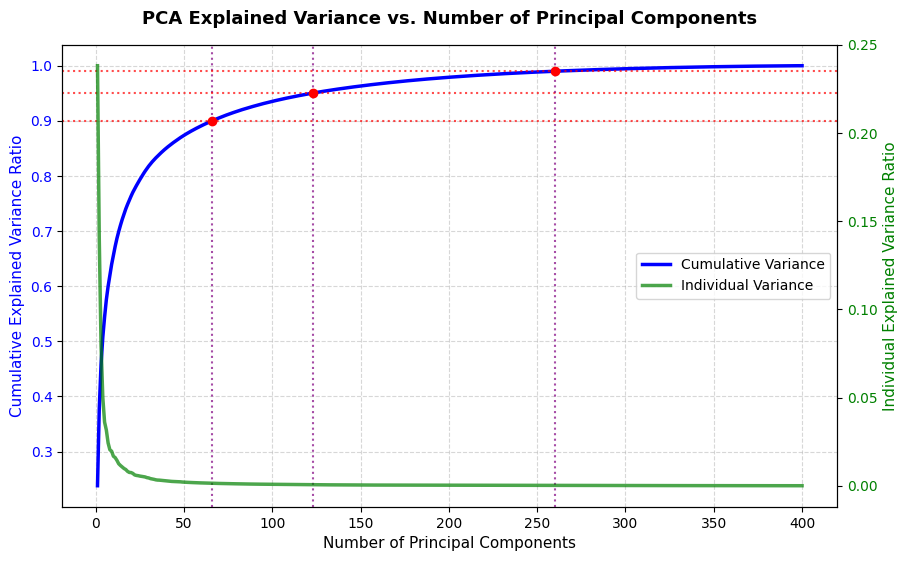

# **Facial Image Reconstruction Quality across Component Limits (k) (Task 3):**

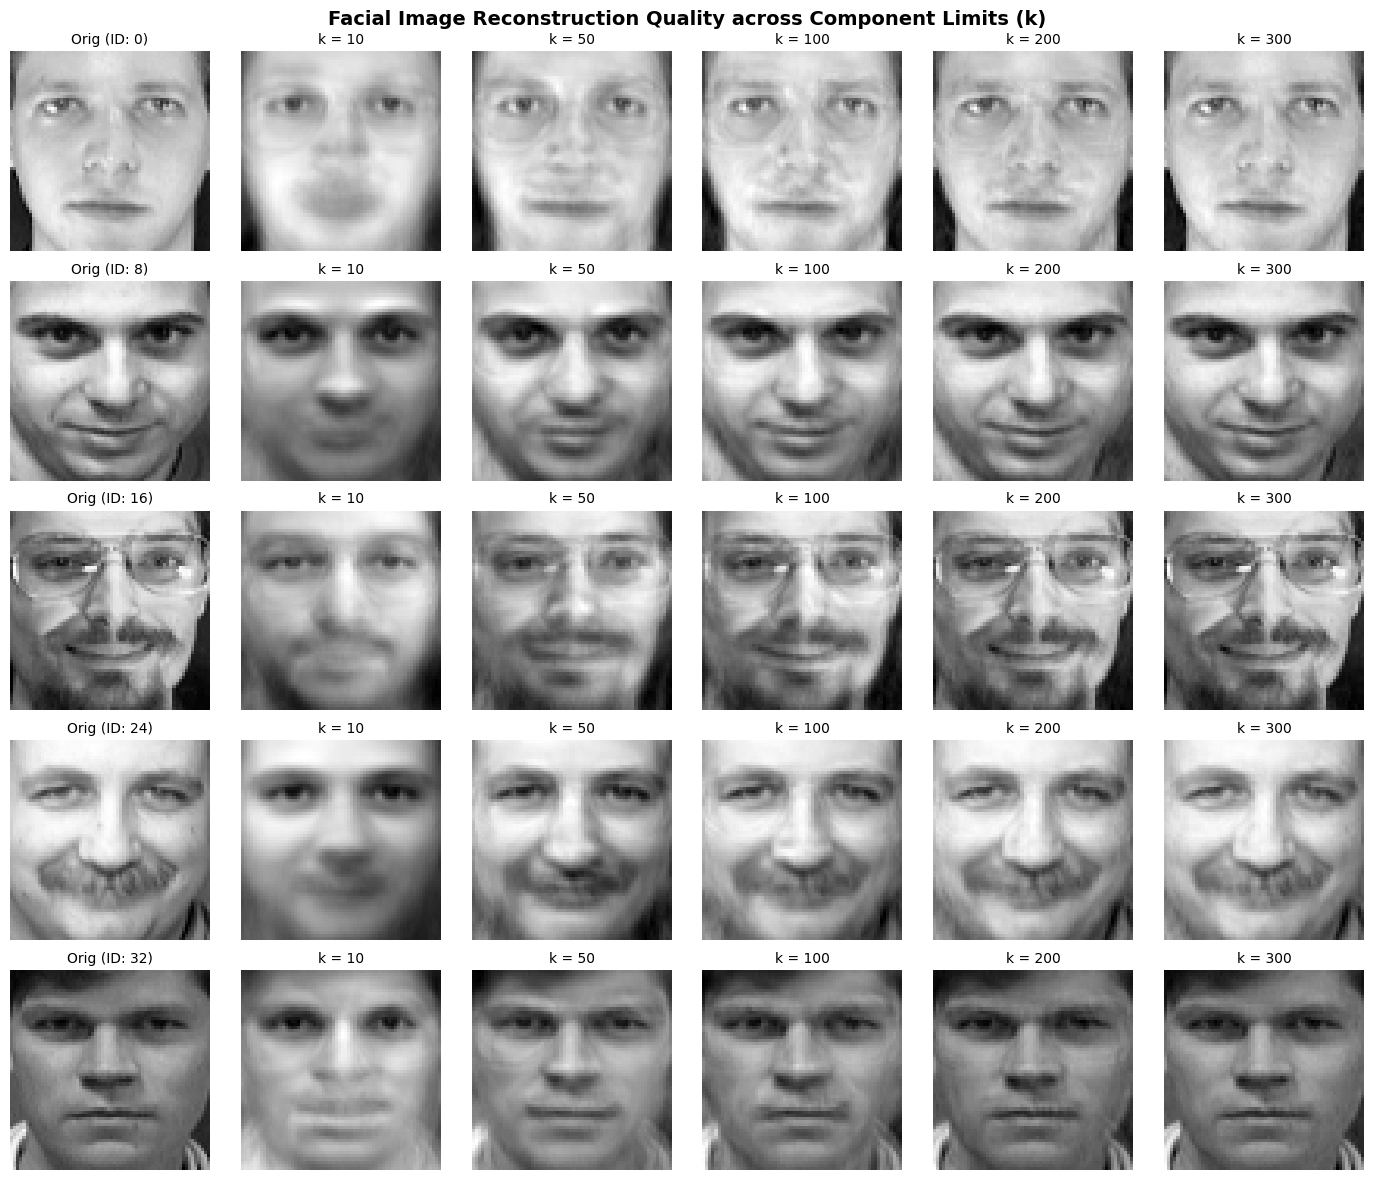

# **Reconstruction Mean Squared Error (MSE) vs. Component Count (k) (Task 3):**

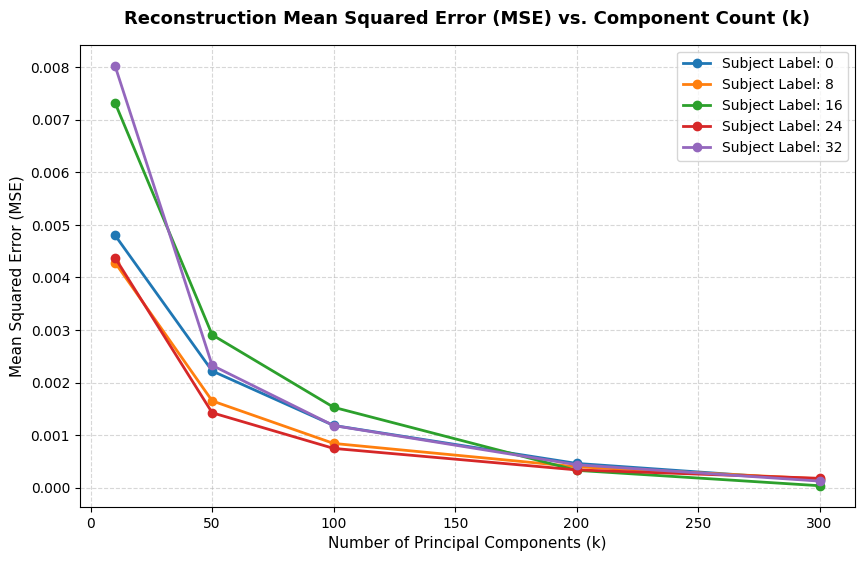

# **First 15 Eigenfaces (Task 4):**

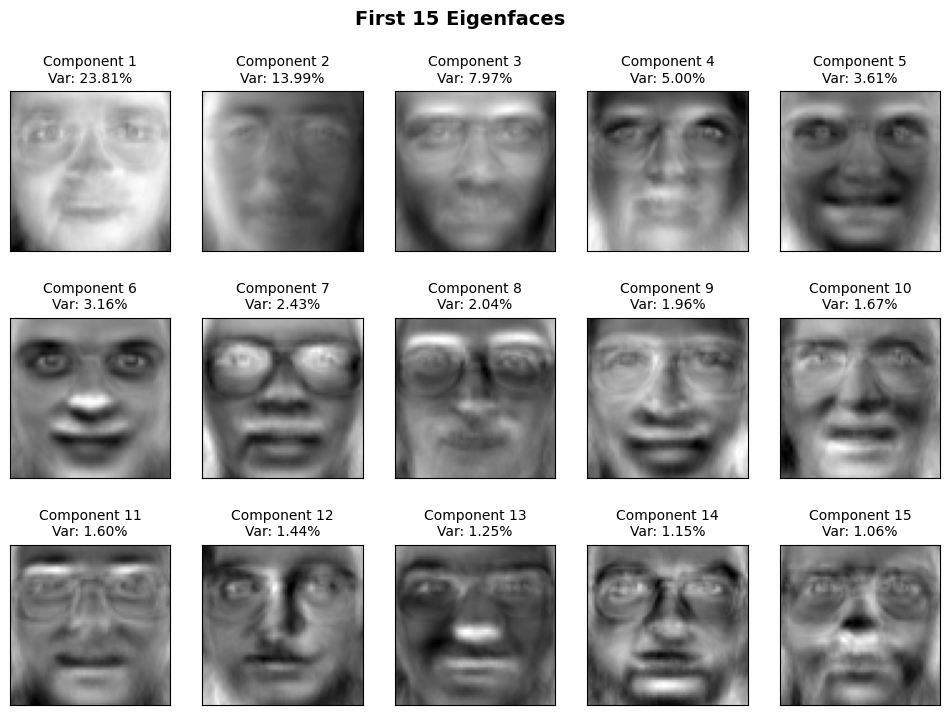

# **Logistic Regression Performance: Raw vs. PCA Features (Accuracy vs. Training Time) (Task 5):**

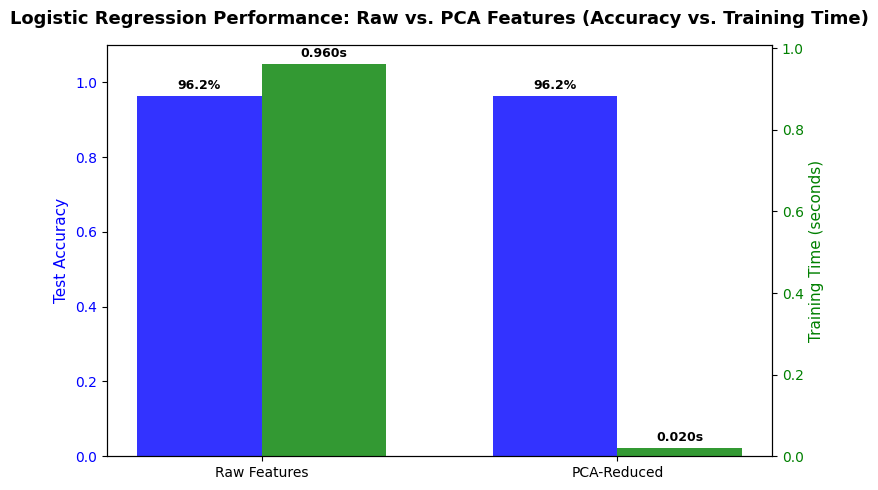

# **Prediction Accuracy Breakdown: Linear vs. Non-Linear Models (Task 6):**

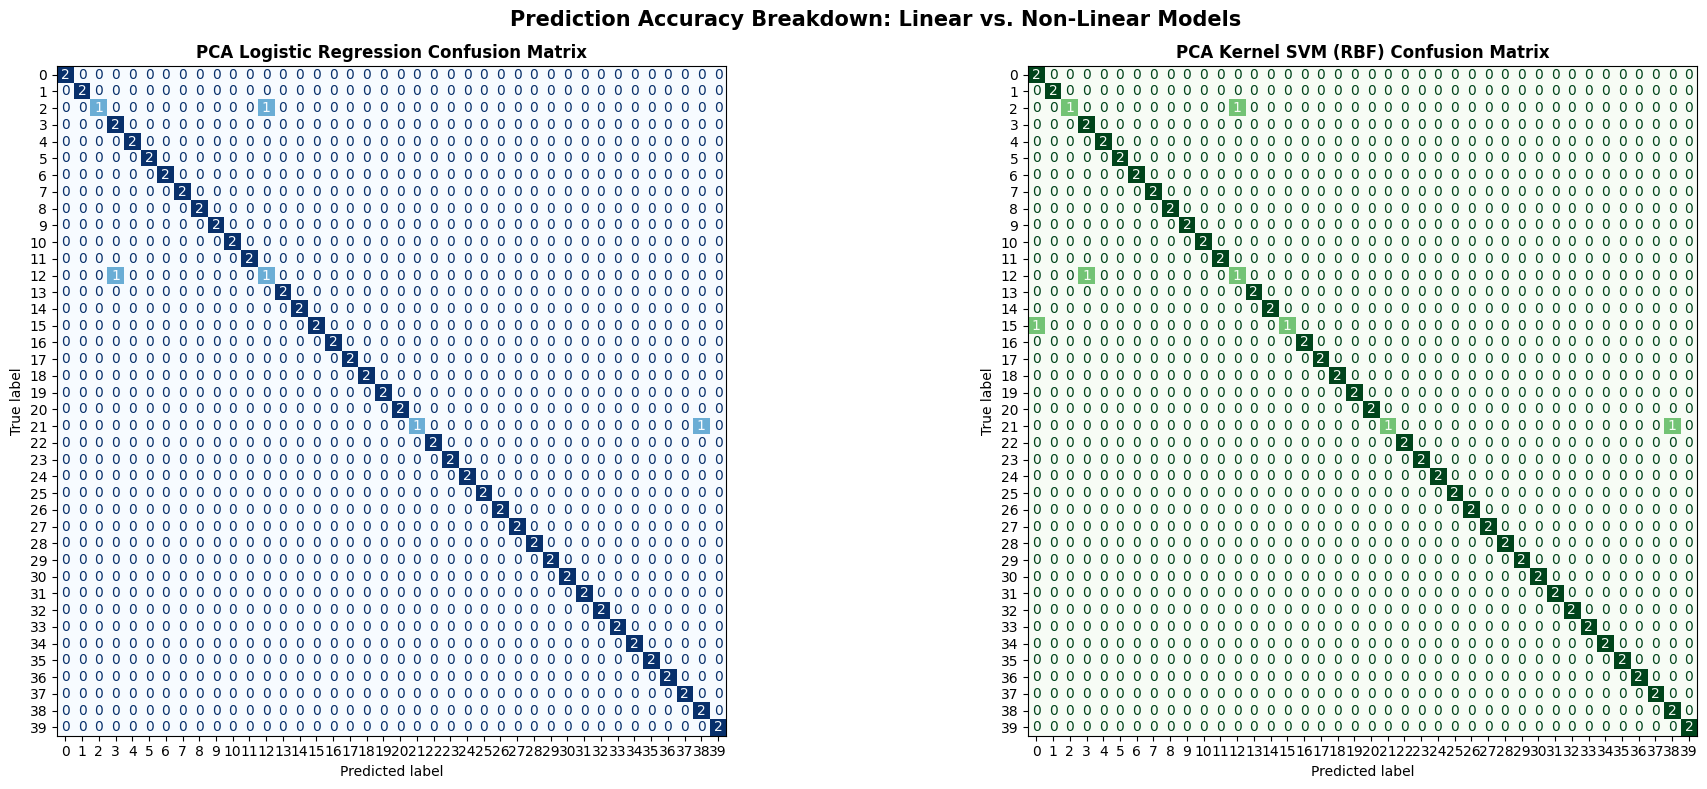

# **Comprehensive Model Summary: Test Accuracy vs. Training Time (Task 8):**

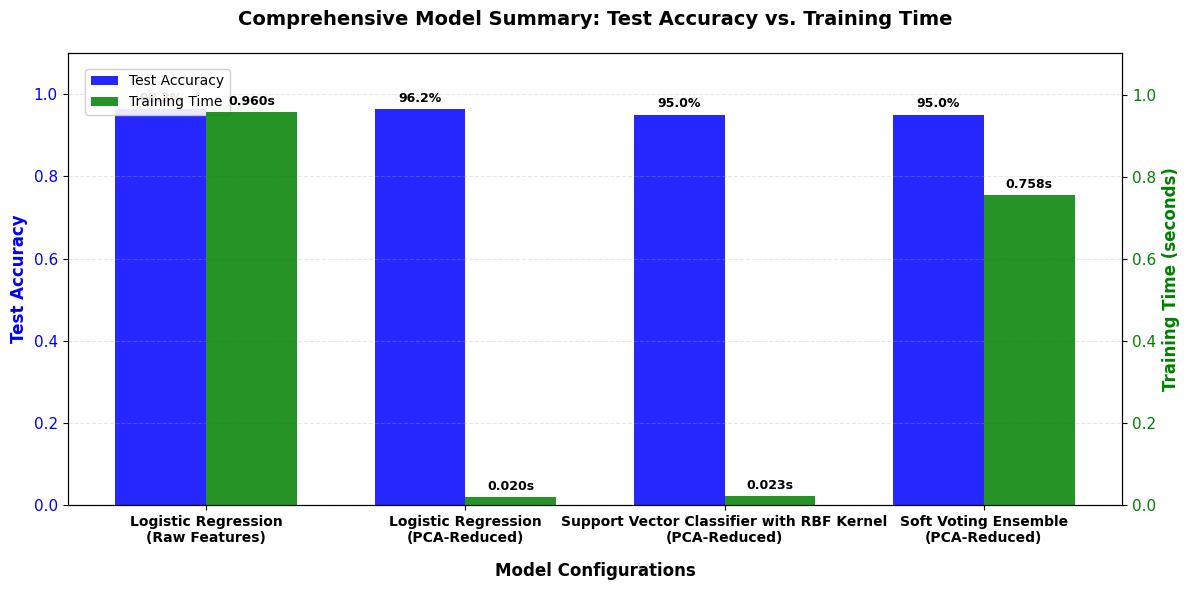